In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [3]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.9

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 90.0% of data
Dataset shape: (38491, 1)
Date range: 2015-10-10 04:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-10-10 04:00:01   53.0
2015-10-10 05:00:01  111.0
2015-10-10 06:00:01  115.0
2015-10-10 07:00:01  154.0
2015-10-10 08:00:01  137.0


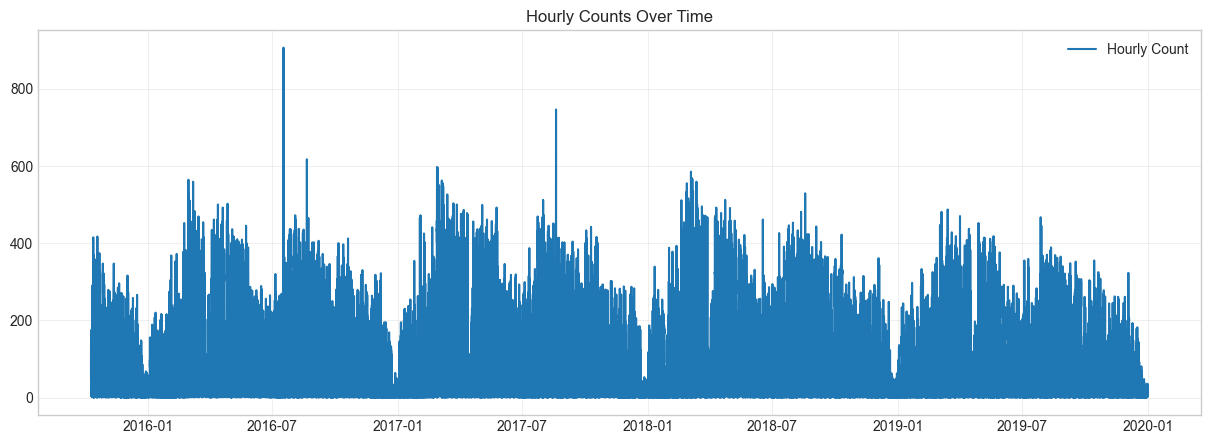

In [4]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [5]:
# =============================================================================
# PART 2: TRAIN / VALIDATION / TEST SPLIT
# =============================================================================

# Define split sizes
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# Identify where the actual values end (before missing values)
# Based on your info: training data ends Dec 31, 2019
# The missing 1440 values are AFTER this date

# Split the data that HAS values
df_with_values = df[df['value'].notna()].copy()

print(f"Data with values: {len(df_with_values)} observations")
print(f"Date range with values: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create splits
# Test set: We don't have values yet (the 1440 missing ones) - we'll forecast these
# Validation set: Last 1440 observations WITH values (for hyperparameter tuning)
# Training set: Everything before validation

train_end_idx = len(df_with_values) - FORECAST_HORIZON
val_end_idx = len(df_with_values)

train = df_with_values.iloc[:train_end_idx].copy()
validation = df_with_values.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*60}")
print(f"SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")
print(f"Test set:       {FORECAST_HORIZON:,} obs | To be forecasted (Jan-Feb 2020)")
print(f"{'='*60}")

# Extract the series
y_train = train['value']
y_val = validation['value']

Data with values: 37052 observations
Date range with values: 2015-10-10 04:00:01 to 2019-12-31 23:00:01

SPLIT SUMMARY
Training set:   35,612 obs | 2015-10-10 04:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01
Test set:       1,440 obs | To be forecasted (Jan-Feb 2020)


In [6]:
# =============================================================================
# PART 3: FOURIER FEATURES FOR WEEKLY SEASONALITY
# =============================================================================

# SARIMA will handle daily seasonality (m=24)
# Fourier terms will handle weekly seasonality (period=168)

# We'll test different K values (number of Fourier pairs)
# K=1: captures basic weekly pattern
# K=2-3: captures more complex weekly patterns
# K=4: very flexible (risk of overfitting)

WEEKLY_PERIOD = 168  # 7 days * 24 hours
FOURIER_K = 3  # Number of Fourier pairs (we'll tune this)

def create_fourier_features(index, period, k):
    """
    Create Fourier features for a given period.
    
    Parameters:
    -----------
    index : DatetimeIndex
        The datetime index
    period : int
        The seasonal period (168 for weekly with hourly data)
    k : int
        Number of Fourier pairs (sin/cos)
    
    Returns:
    --------
    DataFrame with Fourier features
    """
    n = len(index)
    t = np.arange(n)
    
    fourier_features = pd.DataFrame(index=index)
    
    for i in range(1, k + 1):
        fourier_features[f'sin_{period}_{i}'] = np.sin(2 * np.pi * i * t / period)
        fourier_features[f'cos_{period}_{i}'] = np.cos(2 * np.pi * i * t / period)
    
    return fourier_features

# Create Fourier features for training and validation
fourier_train = create_fourier_features(train.index, WEEKLY_PERIOD, FOURIER_K)
fourier_val = create_fourier_features(validation.index, WEEKLY_PERIOD, FOURIER_K)

print(f"Fourier features created with K={FOURIER_K} pairs")
print(f"Feature columns: {list(fourier_train.columns)}")
print(f"\nTraining Fourier shape: {fourier_train.shape}")
print(f"Validation Fourier shape: {fourier_val.shape}")

# Preview
print(f"\nFourier features preview:\n{fourier_train.head()}")

Fourier features created with K=3 pairs
Feature columns: ['sin_168_1', 'cos_168_1', 'sin_168_2', 'cos_168_2', 'sin_168_3', 'cos_168_3']

Training Fourier shape: (35612, 6)
Validation Fourier shape: (1440, 6)

Fourier features preview:
                     sin_168_1  cos_168_1  sin_168_2  cos_168_2  sin_168_3  \
date                                                                         
2015-10-10 04:00:01   0.000000   1.000000   0.000000   1.000000   0.000000   
2015-10-10 05:00:01   0.037391   0.999301   0.074730   0.997204   0.111964   
2015-10-10 06:00:01   0.074730   0.997204   0.149042   0.988831   0.222521   
2015-10-10 07:00:01   0.111964   0.993712   0.222521   0.974928   0.330279   
2015-10-10 08:00:01   0.149042   0.988831   0.294755   0.955573   0.433884   

                     cos_168_3  
date                            
2015-10-10 04:00:01   1.000000  
2015-10-10 05:00:01   0.993712  
2015-10-10 06:00:01   0.974928  
2015-10-10 07:00:01   0.943883  
2015-10-10 08:00:01 

In [ ]:
# =============================================================================
# PART 3a: BOX-COX TRANSFORMATION
# =============================================================================
from scipy.stats import boxcox
from scipy.special import inv_boxcox

print(f"Applying Box-Cox Transformation to stabilize variance...")

# 1. Handle non-positive values
# Box-Cox requires strictly positive data (> 0). 
# If we have 0 or negative values, we add an offset constant.
if y_train.min() <= 0:
    # Add offset so the minimum value becomes 1.0
    # For count data with zeros, usually adding 1 is sufficient
    offset = 1.0 - y_train.min()
    print(f"Data contains non-positive values (min: {y_train.min()}).")
    print(f"Adding offset of {offset} to all data before transformation.")
else:
    offset = 0.0

# 2. Apply Box-Cox on training data
# This finds the optimal lambda that maximizes log-likelihood
y_train_shifted = y_train + offset
y_train_transformed, lam = boxcox(y_train_shifted)

# Store original y_train just in case
y_train_original = y_train.copy()

# Update y_train with transformed values for the model
y_train = pd.Series(y_train_transformed, index=y_train.index)

print(f"\nOptimal Lambda found: {lam:.4f}")
if np.isclose(lam, 0, atol=0.05):
    print("Lambda is close to 0, which corresponds to Log Transformation.")
elif np.isclose(lam, 1, atol=0.05):
    print("Lambda is close to 1, implying limited need for transformation.")
    
print(f"Transformed Training Data Range: {y_train.min():.4f} to {y_train.max():.4f}")

# 3. Define helper for inverse transformation (for predictions)
def inverse_boxcox(y_transformed, lambda_, offset_):
    """
    Inverse Box-Cox transformation to get back to original scale.
    """
    y_inv = inv_boxcox(y_transformed, lambda_)
    return y_inv - offset_

print("\nNOTE: y_train is now transformed.")
print("The model will be trained on the Box-Cox transformed data.")
print("We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.")

In [7]:
# =============================================================================
# PART 4 (SIMPLEST): BASELINE MODEL
# =============================================================================

# Start with a simple, commonly effective model for hourly data
# Based on your ACF/PACF: SARIMA(1,0,1)(1,1,1)[24]

print("Fitting baseline SARIMA(1,0,1)(1,1,1)[24] model...")

baseline_model = SARIMAX(
    y_train,
    exog=fourier_train,
    order=(1, 0, 1),  # AR(1), no differencing, MA(1)
    seasonal_order=(1, 1, 1, 24),  # Seasonal AR(1), diff(1), MA(1), period=24
    enforce_stationarity=False,
    enforce_invertibility=False
)

auto_arima_model = baseline_model.fit(disp=False, maxiter=100)

print("\n" + "=" * 60)
print("BASELINE MODEL FITTED")
print("=" * 60)
print(auto_arima_model.summary())

best_order = (1, 0, 1)
best_seasonal_order = (1, 1, 1, 24)

print(f"\nOrder (p,d,q): {best_order}")
print(f"Seasonal Order (P,D,Q,m): {best_seasonal_order}")
print(f"AIC: {auto_arima_model.aic:.2f}")

Fitting baseline SARIMA(1,0,1)(1,1,1)[24] model...


c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)



BASELINE MODEL FITTED
                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                35612
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood             -172558.869
Date:                            Thu, 05 Feb 2026   AIC                         345139.738
Time:                                    17:45:43   BIC                         345233.007
Sample:                                10-10-2015   HQIC                        345169.424
                                     - 11-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_168_1      0.7303      1.256      0.581      0.561      -1.731       3.192
cos_168_1   

In [ ]:
# =============================================================================
# PART 5: VALIDATION - FORECAST AND EVALUATE
# =============================================================================

# Generate forecasts for validation period
print(f"\nGenerating {FORECAST_HORIZON}-step forecast for validation...")

# Forecast using the statsmodels object (Baseline)
# We use get_forecast for out-of-sample predictions
# Note: logical check to handle either library (Statsmodels vs Pmdarima)
if hasattr(auto_arima_model, 'get_forecast'):
    # Statsmodels syntax
    forecast_result = auto_arima_model.get_forecast(
        steps=FORECAST_HORIZON,
        exog=fourier_val
    )
    val_forecast = forecast_result.predicted_mean
else:
    # Pmdarima syntax
    val_forecast = auto_arima_model.predict(
        n_periods=FORECAST_HORIZON,
        X=fourier_val
    )

# INVERSE BOX-COX TRANSFORM IF APPLIED
# Check if we have transformed the training data 
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming validation forecast using lambda={lam:.4f}")
    val_forecast = inverse_boxcox(val_forecast, lam, offset)

# Create forecast DataFrame
val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': val_forecast,
    'date': y_val.index
}).set_index('date')

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

sarima_metrics = calculate_metrics(
    val_forecast_df['actual'], 
    val_forecast_df['forecast'],
    name="SARIMA VALIDATION"
)


Generating 1440-step forecast for validation...

METRICS SARIMA VALIDATION
RMSE:  53.26
MAE:   41.46
MAPE:  591901900199051904.00% (all data)
MAPE:  416.96% (excluding zeros)


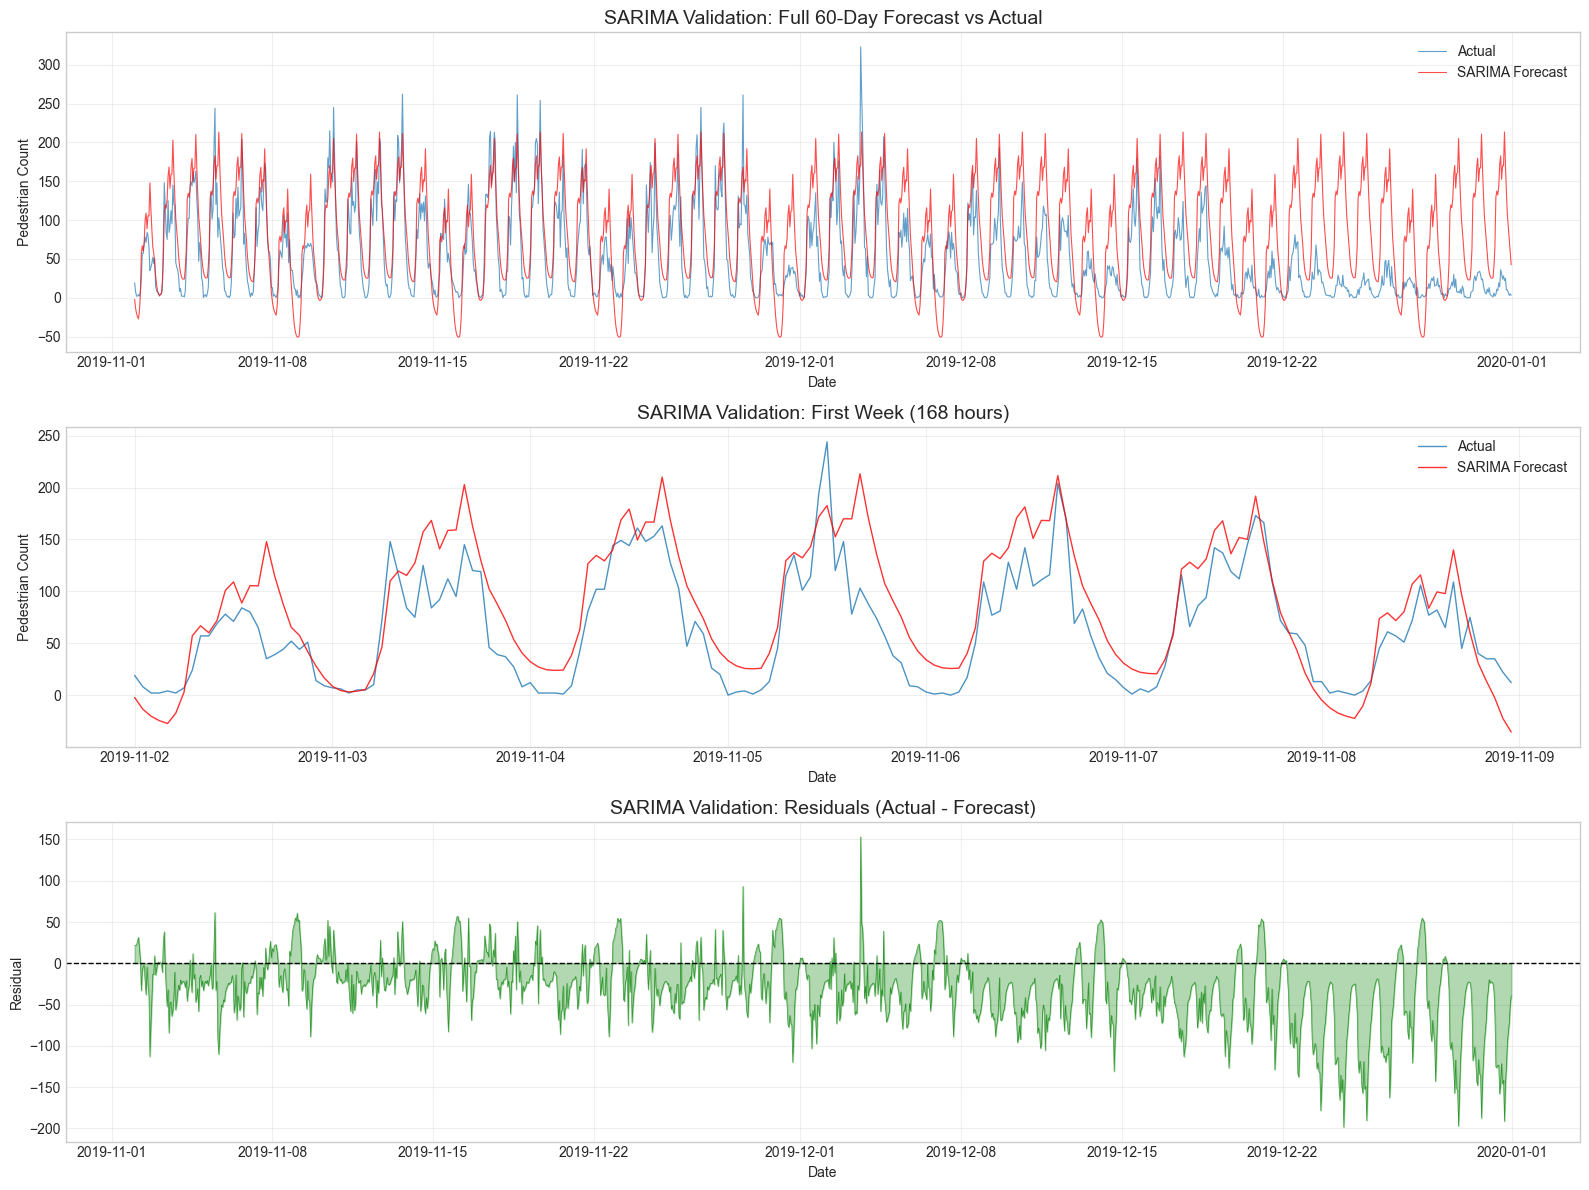

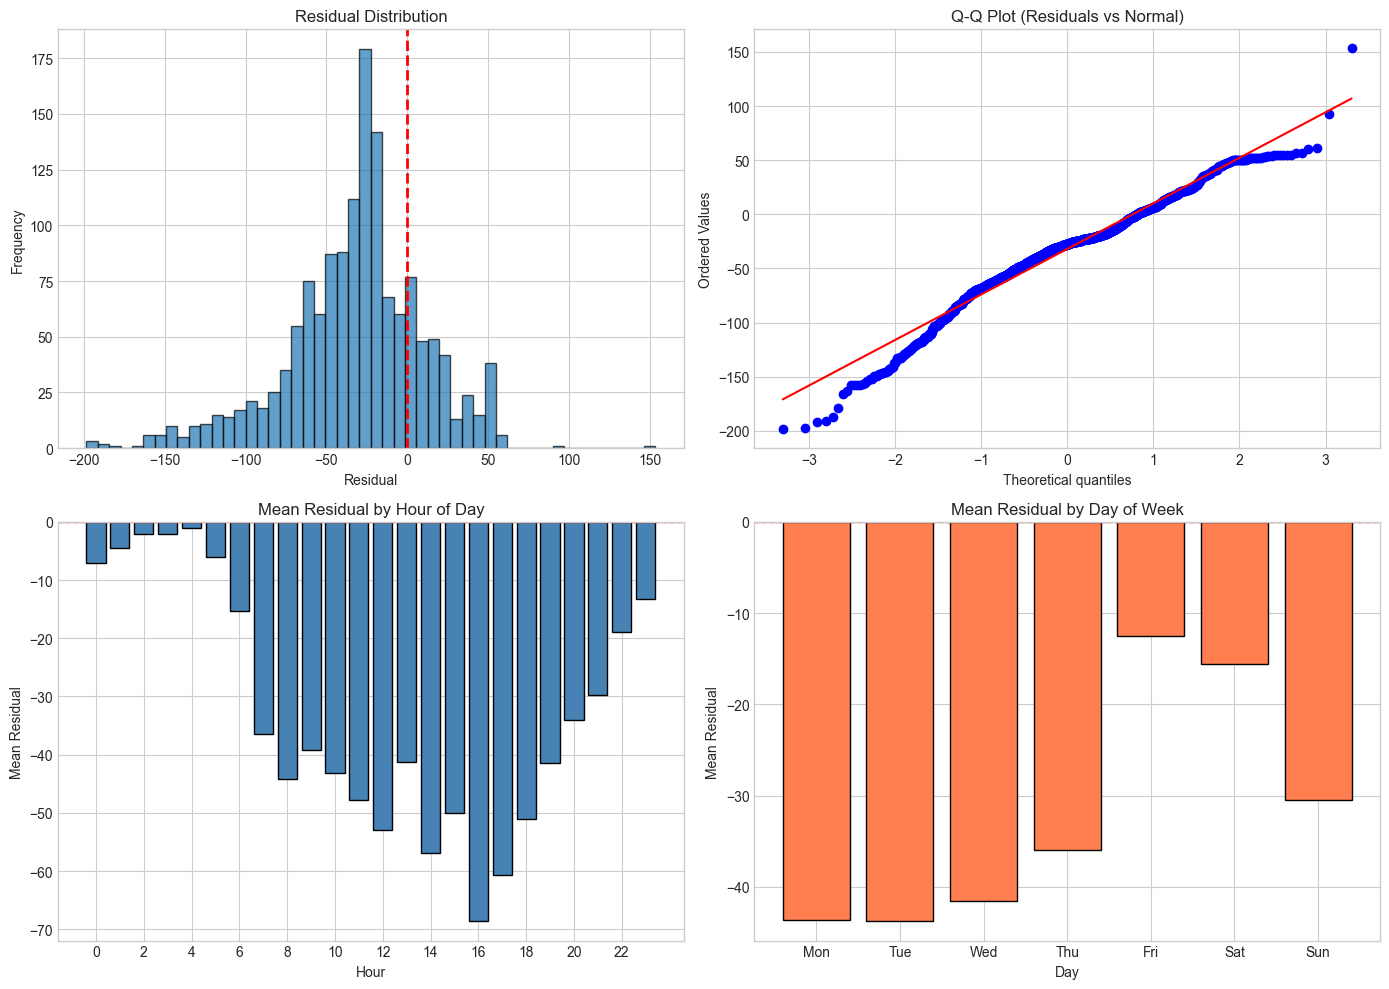

In [9]:
# =============================================================================
# PART 6: VISUALIZATION
# =============================================================================

# Plot 1: Full validation period
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Plot 1a: Full validation forecast vs actual
ax1 = axes[0]
ax1.plot(val_forecast_df.index, val_forecast_df['actual'], 
         label='Actual', alpha=0.7, linewidth=0.8)
ax1.plot(val_forecast_df.index, val_forecast_df['forecast'], 
         label='SARIMA Forecast', alpha=0.7, linewidth=0.8, color='red')
ax1.set_title('SARIMA Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 1b: First week zoom
first_week = val_forecast_df.iloc[:168]  # First 7 days
ax2 = axes[1]
ax2.plot(first_week.index, first_week['actual'], 
         label='Actual', alpha=0.8, linewidth=1)
ax2.plot(first_week.index, first_week['forecast'], 
         label='SARIMA Forecast', alpha=0.8, linewidth=1, color='red')
ax2.set_title('SARIMA Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 1c: Residuals
residuals = val_forecast_df['actual'] - val_forecast_df['forecast']
ax3 = axes[2]
ax3.plot(val_forecast_df.index, residuals, alpha=0.7, linewidth=0.5, color='green')
ax3.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax3.fill_between(val_forecast_df.index, residuals, 0, alpha=0.3, color='green')
ax3.set_title('SARIMA Validation: Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 2: Residual diagnostics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Residual histogram
ax1 = axes[0, 0]
ax1.hist(residuals, bins=50, edgecolor='black', alpha=0.7)
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax1.set_title('Residual Distribution')
ax1.set_xlabel('Residual')
ax1.set_ylabel('Frequency')

# Residual QQ plot
from scipy import stats
ax2 = axes[0, 1]
stats.probplot(residuals, dist="norm", plot=ax2)
ax2.set_title('Q-Q Plot (Residuals vs Normal)')

# Residuals by hour of day
val_forecast_df['hour'] = val_forecast_df.index.hour
hourly_residuals = val_forecast_df.groupby('hour').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
ax3 = axes[1, 0]
ax3.bar(hourly_residuals.index, hourly_residuals.values, color='steelblue', edgecolor='black')
ax3.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax3.set_title('Mean Residual by Hour of Day')
ax3.set_xlabel('Hour')
ax3.set_ylabel('Mean Residual')
ax3.set_xticks(range(0, 24, 2))

# Residuals by day of week
val_forecast_df['dayofweek'] = val_forecast_df.index.dayofweek
daily_residuals = val_forecast_df.groupby('dayofweek').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax4 = axes[1, 1]
ax4.bar(range(7), daily_residuals.values, color='coral', edgecolor='black')
ax4.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax4.set_title('Mean Residual by Day of Week')
ax4.set_xlabel('Day')
ax4.set_ylabel('Mean Residual')
ax4.set_xticks(range(7))
ax4.set_xticklabels(day_names)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# PART 7: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

# Now that we've validated our model, retrain on ALL available data
# (training + validation) before making the final forecast

print("Retraining SARIMA on full data (train + validation)...")

# Combine train and validation
full_train = pd.concat([train, validation])
y_full = full_train['value']

# APPLY BOX-COX IF IT WAS USED BEFORE
if 'lam' in locals() and 'offset' in locals():
    print(f"Applying Box-Cox to full dataset with lambda={lam:.4f}")
    y_full_shifted = y_full + offset
    # Use the same lambda as found in training for consistency
    y_full_transformed = boxcox(y_full_shifted, lmbda=lam)
    y_full = pd.Series(y_full_transformed, index=y_full.index)

# Create Fourier features for full training data
fourier_full = create_fourier_features(full_train.index, WEEKLY_PERIOD, FOURIER_K)

# Fit final model with best parameters found by auto_arima
final_model = SARIMAX(
    y_full,
    exog=fourier_full,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_model_fit = final_model.fit(disp=False)

print("\nFinal Model Summary:")
print(final_model_fit.summary())

Retraining SARIMA on full data (train + validation)...


c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)



Final Model Summary:
                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                37052
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood             -179123.467
Date:                            Thu, 05 Feb 2026   AIC                         358268.933
Time:                                    17:51:47   BIC                         358362.639
Sample:                                10-10-2015   HQIC                        358298.703
                                     - 12-31-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_168_1      0.8520      1.218      0.699      0.484      -1.536       3.240
cos_168_1    

In [ ]:
# =============================================================================
# GENERATE FORECAST FOR TEST PERIOD (the 1440 missing values)
# =============================================================================

# Create future dates for forecast period
last_date = full_train.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"\nForecast period: {future_dates.min()} to {future_dates.max()}")

# Create Fourier features for forecast period
# IMPORTANT: We need to continue the Fourier sequence properly
def create_fourier_features_forecast(future_index, train_index, period, k):
    """
    Create Fourier features for forecast period, continuing from training.
    """
    # Total length from start of training to end of forecast
    n_train = len(train_index)
    n_forecast = len(future_index)
    
    # Time indices for forecast (continuing from training)
    t = np.arange(n_train, n_train + n_forecast)
    
    fourier_features = pd.DataFrame(index=future_index)
    
    for i in range(1, k + 1):
        fourier_features[f'sin_{period}_{i}'] = np.sin(2 * np.pi * i * t / period)
        fourier_features[f'cos_{period}_{i}'] = np.cos(2 * np.pi * i * t / period)
    
    return fourier_features

fourier_forecast = create_fourier_features_forecast(
    future_dates, full_train.index, WEEKLY_PERIOD, FOURIER_K
)

# Generate final forecast
final_forecast = final_model_fit.get_forecast(
    steps=FORECAST_HORIZON,
    exog=fourier_forecast
)

# Extract predictions and confidence intervals
forecast_mean = final_forecast.predicted_mean
forecast_ci = final_forecast.conf_int(alpha=0.05)  # 95% CI

# INVERSE BOX-COX TRANSFORM IF APPLIED
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming final forecast using lambda={lam:.4f}")
    forecast_mean = inverse_boxcox(forecast_mean, lam, offset)
    forecast_ci = inverse_boxcox(forecast_ci, lam, offset)

# Create forecast DataFrame
final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': forecast_mean.values,
    'lower_ci': forecast_ci.iloc[:, 0].values,
    'upper_ci': forecast_ci.iloc[:, 1].values
}).set_index('date')

# Clip negative forecasts to 0 (counts can't be negative)
final_forecast_df['forecast'] = final_forecast_df['forecast'].clip(lower=0)
final_forecast_df['lower_ci'] = final_forecast_df['lower_ci'].clip(lower=0)
final_forecast_df['upper_ci'] = final_forecast_df['upper_ci'].clip(lower=0)

print(f"\nFinal Forecast Summary:")
print(final_forecast_df.describe())


Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Final Forecast Summary:
          forecast  lower_ci     upper_ci
count  1440.000000    1440.0  1440.000000
mean     29.944036       0.0   136.017589
std      25.738631       0.0    34.893018
min       0.000000       0.0    45.303642
25%       4.699333       0.0   112.931362
50%      22.497814       0.0   137.025831
75%      54.599968       0.0   164.483386
max      82.179219       0.0   204.691610


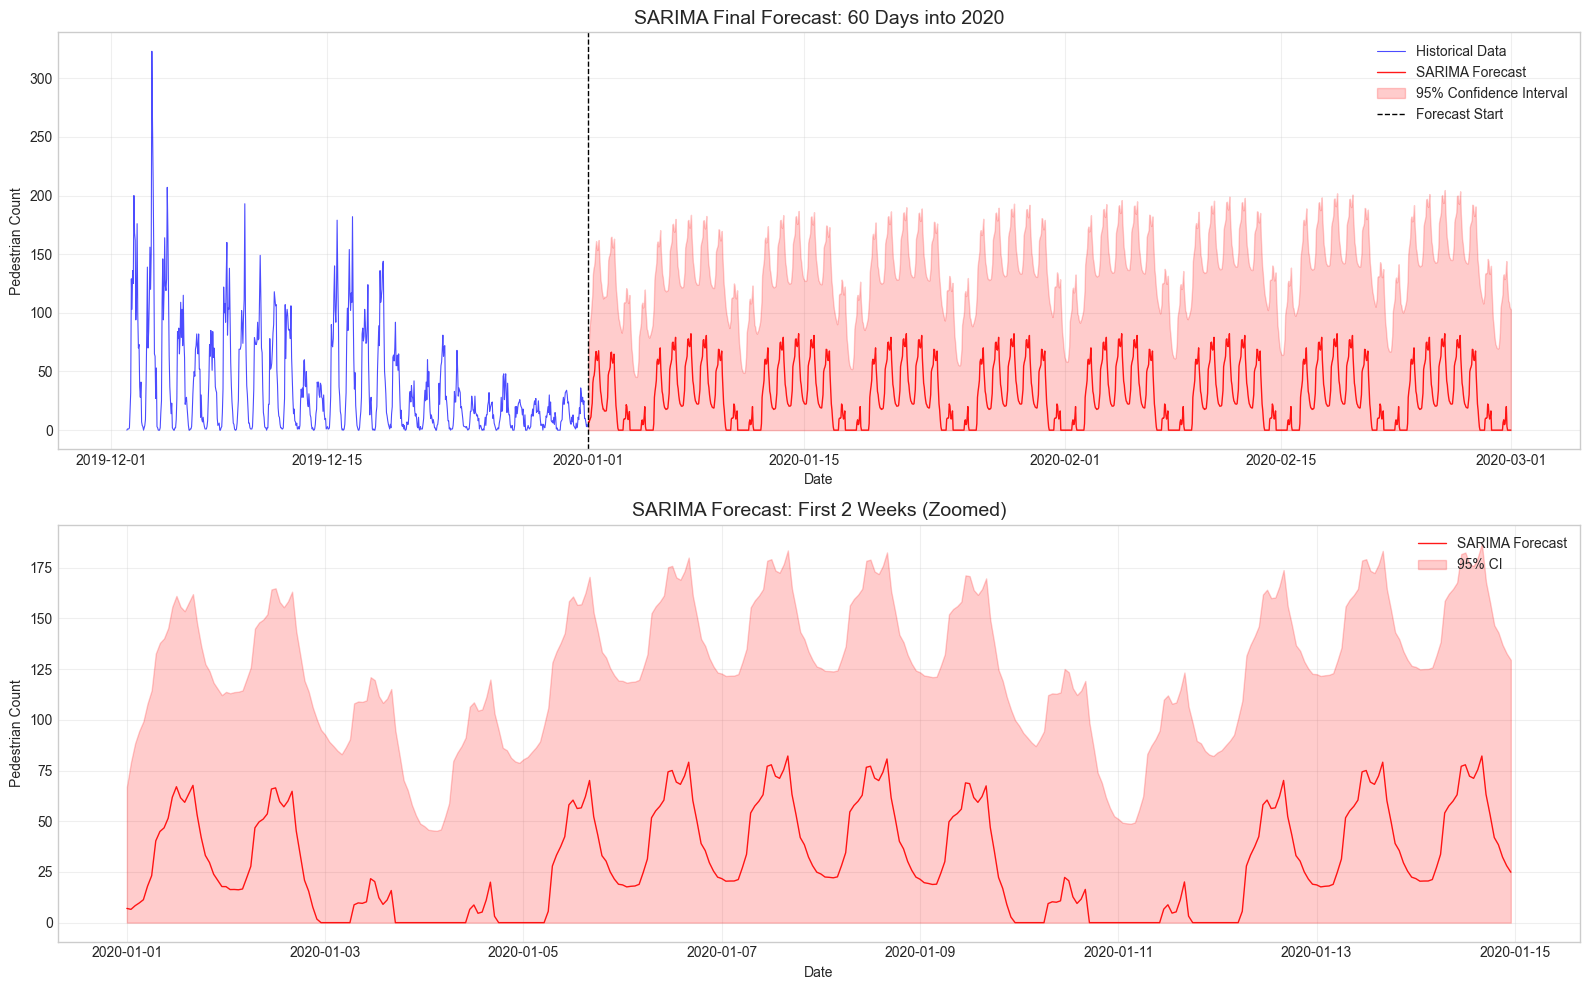

In [12]:
# =============================================================================
# PART 8: VISUALIZE FINAL FORECAST
# =============================================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Historical data + Forecast
ax1 = axes[0]

# Last 30 days of training data for context
context_data = full_train.iloc[-720:]  # Last 30 days

ax1.plot(context_data.index, context_data['value'], 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(final_forecast_df.index, final_forecast_df['forecast'], 
         label='SARIMA Forecast', alpha=0.9, linewidth=1, color='red')
ax1.fill_between(final_forecast_df.index, 
                  final_forecast_df['lower_ci'], 
                  final_forecast_df['upper_ci'],
                  alpha=0.2, color='red', label='95% Confidence Interval')
ax1.axvline(x=full_train.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('SARIMA Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: First 2 weeks of forecast (zoomed)
first_two_weeks = final_forecast_df.iloc[:336]  # 14 days
ax2 = axes[1]
ax2.plot(first_two_weeks.index, first_two_weeks['forecast'], 
         label='SARIMA Forecast', alpha=0.9, linewidth=1, color='red')
ax2.fill_between(first_two_weeks.index, 
                  first_two_weeks['lower_ci'], 
                  first_two_weeks['upper_ci'],
                  alpha=0.2, color='red', label='95% CI')
ax2.set_title('SARIMA Forecast: First 2 Weeks (Zoomed)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# PART 4: AUTO ARIMA - THOROUGH SEARCH
# =============================================================================

# This will take a while due to thorough search!
# We're searching for best (p,d,q)(P,D,Q)[24] with Fourier exogenous variables

print("Starting Auto ARIMA search (this may take 10-30+ minutes)...")
print("Parameters: m=24 (daily seasonality), d=0 (stationary), thorough search")
print("-" * 60)

# Thorough search parameters
auto_arima_model = pm.auto_arima(
    y_train,
    
    # Exogenous variables (Fourier terms for weekly seasonality)
    X=fourier_train,
    
    # Seasonal settings
    seasonal=True,
    m=24,  # Daily seasonality (24 hours)
    
    # Differencing
    d=0,  # Non-seasonal differencing (already stationary based on ADF)
    D=None,  # Let auto_arima decide seasonal differencing (will test 0 and 1)
    max_D=1,
    
    # AR and MA ranges (thorough search)
    start_p=0,
    max_p=4,
    start_q=0,
    max_q=4,
    
    # Seasonal AR and MA ranges
    start_P=0,
    max_P=3,
    start_Q=0,
    max_Q=3,
    
    # Search settings
    stepwise=False,  # False = exhaustive search (slower but thorough)
    n_fits=50,  # Max models to fit (increase for more thorough search)
    
    # Information criterion
    information_criterion='aic',
    
    # Other settings
    trace=True,  # Print progress
    error_action='ignore',
    suppress_warnings=True,
    
    # Parallel processing (set n_jobs=-1 to use all cores)
    n_jobs=-1
)

print("\n" + "=" * 60)
print("AUTO ARIMA RESULTS")
print("=" * 60)
print(auto_arima_model.summary())

# Store best parameters
best_order = auto_arima_model.order
best_seasonal_order = auto_arima_model.seasonal_order

print(f"\nBest Order (p,d,q): {best_order}")
print(f"Best Seasonal Order (P,D,Q,m): {best_seasonal_order}")
print(f"AIC: {auto_arima_model.aic():.2f}")